<a href="https://colab.research.google.com/github/vanessapeterka/a-sigla/blob/main/Imagens_Sentinel_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import requests, zipfile, io, os
from datetime import datetime

USER = "seu_email_cdse"
PASS = "sua_senha_cdse"

def get_token():
    r = requests.post(
        "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token",
        data={"client_id": "cdse-public", "username": USER,
              "password": PASS, "grant_type": "password"})
    r.raise_for_status()
    return r.json()["access_token"]

def buscar(lat, lon, dia, produto="OL_2_WFR___"):
    filtro = (
        "Collection/Name eq 'SENTINEL-3' and "
        "Attributes/OData.CSC.StringAttribute/any(att:att/Name eq 'productType' "
        f"and att/OData.CSC.StringAttribute/Value eq '{produto}') and "
        f"OData.CSC.Intersects(area=geography'SRID=4326;POINT({lon} {lat})') and "
        f"ContentDate/Start gt {dia}T00:00:00.000Z and "
        f"ContentDate/Start lt {dia}T23:59:59.000Z"
    )
    r = requests.get("https://catalogue.dataspace.copernicus.eu/odata/v1/Products",
                     params={"$filter": filtro, "$orderby": "ContentDate/Start", "$top": 20})
    r.raise_for_status()
    return r.json()["value"]

def baixar(produto, pasta="s3_olci"):
    os.makedirs(pasta, exist_ok=True)
    token = get_token()
    s = requests.Session()
    s.headers.update({"Authorization": f"Bearer {token}"})
    url = f"https://download.dataspace.copernicus.eu/odata/v1/Products({produto['Id']})/$value"
    r = s.get(url, stream=True)
    r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        z.extractall(pasta)
    return os.path.join(pasta, produto["Name"])  # pasta .SAFE

In [ ]:
pontos = {
    "P1": (-22.837528, -43.181528),
    # "P2": (lat, lon),
}
dia = "2026-09-26"

cenas = {}
for nome, (lat, lon) in pontos.items():
    for p in buscar(lat, lon, dia):
        cenas[p["Id"]] = p      # evita baixar a mesma cena duas vezes

for p in cenas.values():
    print(p["Name"], p["ContentDate"]["Start"])

S3A_OL_2_WFR____20260926T123105_20260926T123405_20260927T181313_0179_144_223_3240_MAR_O_NT_004.SEN3 2026-09-26T12:31:05.133563Z
S3A_OL_2_WFR____20260926T123105_20260926T123405_20260926T141043_0179_144_223_3240_MAR_O_NR_004.SEN3 2026-09-26T12:31:05.133669Z


In [ ]:
import xarray as xr, numpy as np
from scipy.spatial import cKDTree

def extrair(safe, pontos):
    geo = xr.open_dataset(f"{safe}/geo_coordinates.nc")
    chl = xr.open_dataset(f"{safe}/chl_oc4me.nc")["CHL_OC4ME"]
    flags = xr.open_dataset(f"{safe}/wqsf.nc")["WQSF"]

    lat = geo["latitude"].values
    lon = geo["longitude"].values
    tree = cKDTree(np.c_[lat.ravel(), lon.ravel()])

    out = {}
    for nome, (la, lo) in pontos.items():
        d, idx = tree.query([la, lo])
        i, j = np.unravel_index(idx, lat.shape)
        out[nome] = {
            "dist_graus": float(d),
            "chl_mg_m3": float(10 ** chl.values[i, j]),  # confira o atributo: CHL_OC4ME vem em log10
            "wqsf": int(flags.values[i, j]),
        }
    return out

In [ ]:
!pip install -q xarray netCDF4 scipy requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 72.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 68.5 MB/s eta 0:00:00


In [ ]:
import requests, os, zipfile
from getpass import getpass

USER = input("Email CDSE: ")
PASS = getpass("Senha CDSE: ")

def get_token():
    r = requests.post(
        "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token",
        data={"client_id": "cdse-public", "username": USER,
              "password": PASS, "grant_type": "password"})
    print("Login status:", r.status_code)
    r.raise_for_status()
    return r.json()["access_token"]

token = get_token()

Email CDSE: vanessa.peterka@gmail.com
Senha CDSE: ··········
Login status: 200


In [ ]:
def buscar(lat, lon, dia, produto="OL_2_WFR___"):
    filtro = (
        "Collection/Name eq 'SENTINEL-3' and "
        "Attributes/OData.CSC.StringAttribute/any(att:att/Name eq 'productType' "
        f"and att/OData.CSC.StringAttribute/Value eq '{produto}') and "
        f"OData.CSC.Intersects(area=geography'SRID=4326;POINT({lon} {lat})') and "
        f"ContentDate/Start gt {dia}T00:00:00.000Z and "
        f"ContentDate/Start lt {dia}T23:59:59.000Z"
    )
    r = requests.get("https://catalogue.dataspace.copernicus.eu/odata/v1/Products",
                     params={"$filter": filtro, "$orderby": "ContentDate/Start", "$top": 20})
    print("Busca status:", r.status_code)
    if r.status_code != 200:
        print(r.text[:500])
    r.raise_for_status()
    return r.json()["value"]

pontos = {"P1": (-22.837528, -43.181528)}
dia = "2026-09-26"

cenas = {}
for nome, (lat, lon) in pontos.items():
    for p in buscar(lat, lon, dia):
        cenas[p["Id"]] = p

print("Cenas encontradas:", len(cenas))
for p in cenas.values():
    print(p["Name"], p["ContentDate"]["Start"])

Busca status: 200
Cenas encontradas: 2
S3A_OL_2_WFR____20260926T123105_20260926T123405_20260927T181313_0179_144_223_3240_MAR_O_NT_004.SEN3 2026-09-26T12:31:05.133563Z
S3A_OL_2_WFR____20260926T123105_20260926T123405_20260926T141043_0179_144_223_3240_MAR_O_NR_004.SEN3 2026-09-26T12:31:05.133669Z


In [ ]:
def baixar(p, pasta="s3_olci"):
    os.makedirs(pasta, exist_ok=True)
    token = get_token()
    url = f"https://download.dataspace.copernicus.eu/odata/v1/Products({p['Id']})/$value"
    zpath = os.path.join(pasta, p["Name"] + ".zip")
    with requests.get(url, headers={"Authorization": f"Bearer {token}"}, stream=True) as r:
        print("Download status:", r.status_code)
        r.raise_for_status()
        with open(zpath, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024*1024):
                f.write(chunk)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(pasta)
    os.remove(zpath)
    return os.path.join(pasta, p["Name"])

safe = baixar(list(cenas.values())[0])
print(safe)

Login status: 200
Download status: 200
s3_olci/S3A_OL_2_WFR____20260926T123105_20260926T123405_20260927T181313_0179_144_223_3240_MAR_O_NT_004.SEN3


Pixels dentro do recorte: 33766


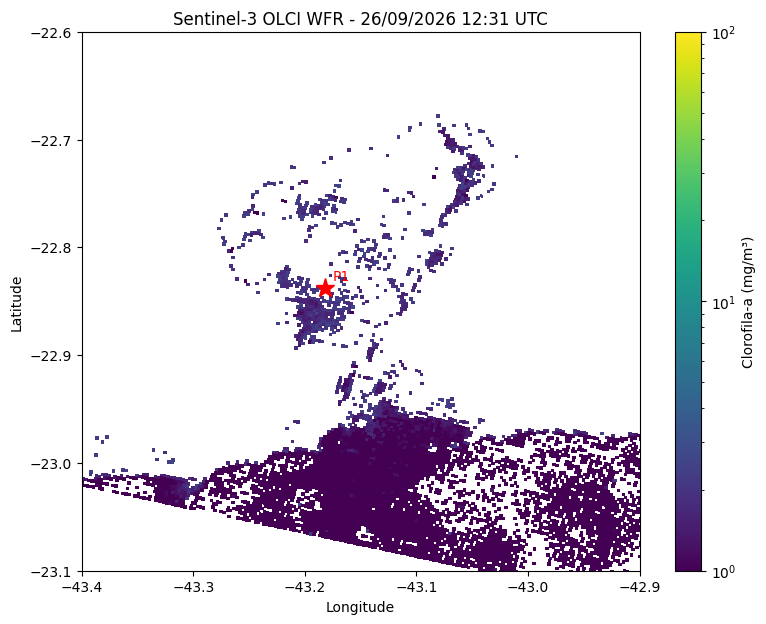

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import xarray as xr
import numpy as np

# Carrega as coordenadas lat/lon e o produto de clorofila do arquivo .SAFE extraído
geo = xr.open_dataset(f"{safe}/geo_coordinates.nc")
lat_arr = geo["latitude"].values
lon_arr = geo["longitude"].values

# O arquivo correto é chlor_a.nc e a variável de concentração de clorofila-a é chlor_a
chl_ds = xr.open_dataset(f"{safe}/chlor_a.nc")["chlor_a"]

# recorte aproximado da baía utilizando as matrizes de coordenadas
dentro = (lat_arr > -23.1) & (lat_arr < -22.6) & (lon_arr > -43.4) & (lon_arr < -42.9)
ii, jj = np.where(dentro)
print("Pixels dentro do recorte:", dentro.sum())

sub = (slice(ii.min(), ii.max() + 1), slice(jj.min(), jj.max() + 1))
chl_val = chl_ds.values[sub]  # Já está em escala linear (mg/m³)

fig, ax = plt.subplots(figsize=(9, 7))
pc = ax.pcolormesh(lon_arr[sub], lat_arr[sub], chl_val, shading="auto",
                   cmap="viridis", norm=LogNorm(vmin=1, vmax=100))
plt.colorbar(pc, label="Clorofila-a (mg/m³)")

for nome_p, (la, lo) in pontos.items():
    ax.plot(lo, la, "r*", markersize=14)
    ax.annotate(nome_p, (lo, la), xytext=(5, 5), textcoords="offset points", color="red")

ax.set_xlim(-43.4, -42.9); ax.set_ylim(-23.1, -22.6)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Sentinel-3 OLCI WFR - 26/09/2026 12:31 UTC")
plt.show()

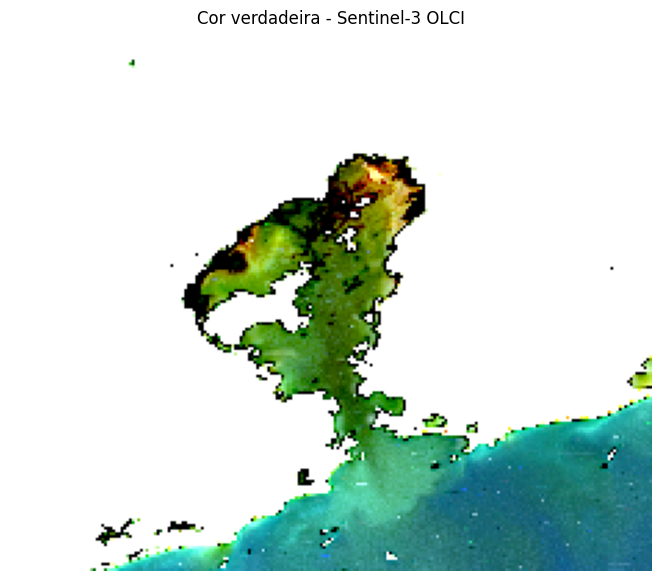

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

# Recalcula o recorte 'sub' caso ele não esteja na memória
if 'sub' not in globals():
    geo = xr.open_dataset(f"{safe}/geo_coordinates.nc")
    lat_arr = geo["latitude"].values
    lon_arr = geo["longitude"].values
    dentro = (lat_arr > -23.1) & (lat_arr < -22.6) & (lon_arr > -43.4) & (lon_arr < -42.9)
    ii, jj = np.where(dentro)
    sub = (slice(ii.min(), ii.max() + 1), slice(jj.min(), jj.max() + 1))

def banda(n):
    return xr.open_dataset(f"{safe}/Oa{n:02d}_reflectance.nc")[f"Oa{n:02d}_reflectance"].values[sub]

R, G, B = banda(8), banda(6), banda(4)   # 665, 560, 490 nm
rgb = np.dstack([R, G, B])
rgb = np.clip(rgb / np.nanpercentile(rgb, 98), 0, 1) ** 0.6   # realce
rgb = np.nan_to_num(rgb, nan=1.0)                              # máscara em branco

plt.figure(figsize=(9, 7))
plt.imshow(rgb)
plt.title("Cor verdadeira - Sentinel-3 OLCI")
plt.axis("off")
plt.show()

Pixels dentro do recorte: 33766


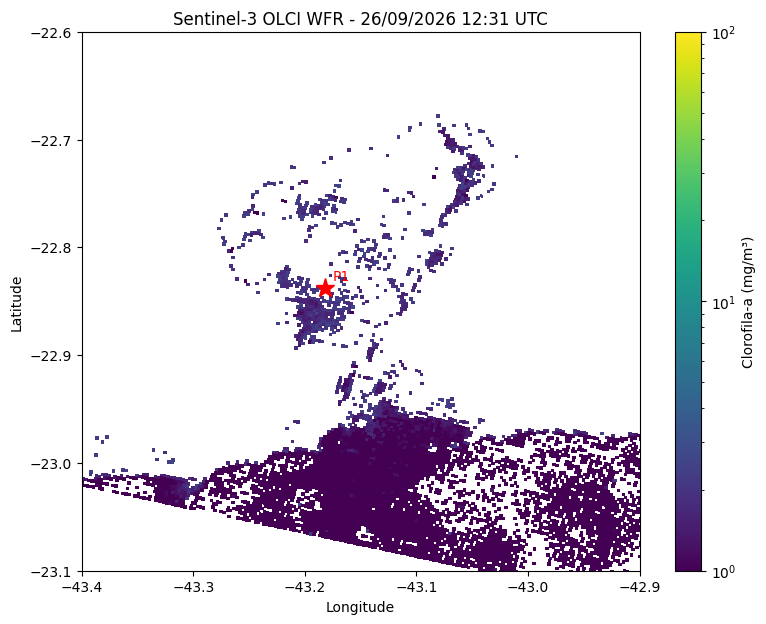

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import xarray as xr
import numpy as np

# Carrega as coordenadas lat/lon e o produto de clorofila do arquivo .SAFE extraído
geo = xr.open_dataset(f"{safe}/geo_coordinates.nc")
lat_arr = geo["latitude"].values
lon_arr = geo["longitude"].values

# O arquivo correto do Sentinel-3 WFR é chlor_a.nc que contém a variável chlor_a
chl_ds = xr.open_dataset(f"{safe}/chlor_a.nc")["chlor_a"]

# Recorte aproximado da baía utilizando as matrizes de coordenadas
dentro = (lat_arr > -23.1) & (lat_arr < -22.6) & (lon_arr > -43.4) & (lon_arr < -42.9)
ii, jj = np.where(dentro)
print("Pixels dentro do recorte:", dentro.sum())

sub = (slice(ii.min(), ii.max() + 1), slice(jj.min(), jj.max() + 1))
chl_val = chl_ds.values[sub]  # Já está em escala linear (mg/m³)

fig, ax = plt.subplots(figsize=(9, 7))
pc = ax.pcolormesh(lon_arr[sub], lat_arr[sub], chl_val, shading="auto",
                   cmap="viridis", norm=LogNorm(vmin=1, vmax=100))
plt.colorbar(pc, label="Clorofila-a (mg/m³)")

for nome_p, (la, lo) in pontos.items():
    ax.plot(lo, la, "r*", markersize=14)
    ax.annotate(nome_p, (lo, la), xytext=(5, 5), textcoords="offset points", color="red")

ax.set_xlim(-43.4, -42.9); ax.set_ylim(-23.1, -22.6)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Sentinel-3 OLCI WFR - 26/09/2026 12:31 UTC")
plt.show()

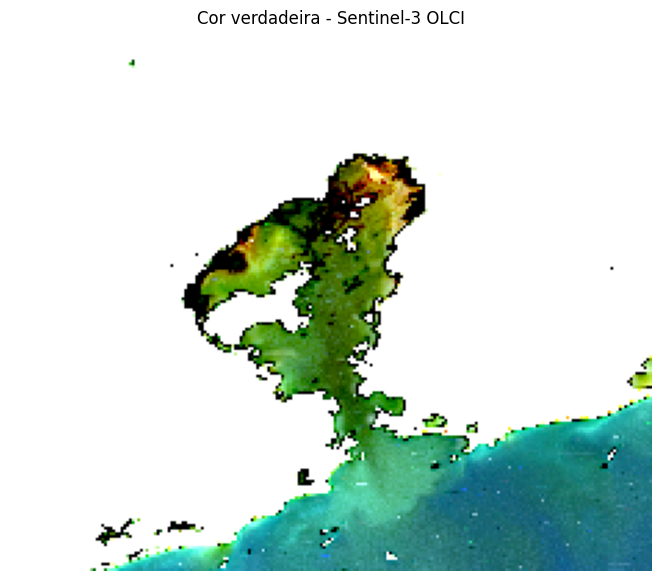

In [ ]:
def banda(n):
    return xr.open_dataset(f"{safe}/Oa{n:02d}_reflectance.nc")[f"Oa{n:02d}_reflectance"].values[sub]

R, G, B = banda(8), banda(6), banda(4)   # 665, 560, 490 nm
rgb = np.dstack([R, G, B])
rgb = np.clip(rgb / np.nanpercentile(rgb, 98), 0, 1) ** 0.6   # realce
rgb = np.nan_to_num(rgb, nan=1.0)                              # máscara em branco

plt.figure(figsize=(9, 7))
plt.imshow(rgb)
plt.title("Cor verdadeira - Sentinel-3 OLCI")
plt.axis("off")
plt.show()